# 02 · EDA Bagian 2 — Riwayat Internal (Pengajuan Lama + Repayment)

**Sumber data**: `previous_applications` (202k baris) + `repayment_history` (1,36 jt cicilan), digabung ke `train_applications`.

| # | Pertanyaan |
|---|---|
| Q1 | Seperti apa struktur riwayat internal, dan siapa yang tidak punya riwayat? |
| Q2 | Apa sebenarnya arti "telat" di data ini? |
| Q3 | Apakah **pola pengajuan** (jumlah, penolakan, frekuensi, nominal) memprediksi gagal bayar? |
| Q4 | Apakah **pinjaman berjalan & suku bunga lama** memprediksi gagal bayar? |
| Q5 | Seberapa kuat **perilaku bayar** (telat, DPD, pelunasan)? |
| Q6 | Apakah **tunggakan aktif saat keputusan** menambah informasi? |
| Q7 | Jendela waktu mana yang paling informatif, dan seberapa andal fitur dengan riwayat pendek? |
| Q8 | Apakah suku bunga **sudah** memperhitungkan riwayat bayar? |
| Q9 | Berapa kenaikan KS dari riwayat internal di atas patokan 0,23? |

**Prinsip waktu**: semua fitur dihitung relatif terhadap `decision_datetime` nasabah masing-masing (*cutoff*). Audit sudah memastikan tidak ada baris setelah cutoff. Tugas kita di sini adalah memastikan **cara menghitungnya** juga benar, misalnya "90 hari terakhir" = 90 hari sebelum cutoff, bukan sebelum tanggal hari ini.

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

tr = E.load("train_applications")
cp = E.load("customer_profiles")
pa = E.load("previous_applications")
rh = E.load("repayment_history")
CUT = tr.select("customer_id", pl.col("decision_datetime").alias("cutoff"))
DAY = 86400

def days_between(later, earlier):
    return ((later - earlier).dt.total_seconds() // DAY).cast(pl.Int64)

### Membangun fitur riwayat per nasabah

Tiga kelompok fitur, masing-masing **satu baris per nasabah**:
- `pa_*`: dari **semua pengajuan lama** (approved, rejected, cancelled)
- `ln_*`: dari **pinjaman lama yang cair**, termasuk beban cicilan yang **masih berjalan** saat cutoff
- `rp_*`: dari **cicilan** (repayment)

Catatan semantik dari audit: cicilan ke-k jatuh tempo tepat k bulan setelah keputusan pinjaman. Jadi pinjaman masih aktif jika `keputusan + tenor bulan > cutoff`, dan ini bisa dihitung untuk pinjaman yang belum punya cicilan sekalipun.

In [2]:
def prev_app_features(pa, cut):
    p = (pa.join(cut, on="customer_id", how="inner")
           .with_columns(age_d=days_between(pl.col("cutoff"), pl.col("decision_datetime")),
                         is_app=pl.col("decision") == "approved",
                         is_rej=pl.col("decision") == "rejected",
                         is_can=pl.col("decision") == "cancelled",
                         cut_ratio=pl.col("approved_amount") / pl.col("requested_amount"))
           .sort("customer_id", "decision_datetime"))
    aggs = [
        pl.len().alias("pa_n"),
        pl.col("is_app").sum().alias("pa_n_approved"),
        pl.col("is_rej").sum().alias("pa_n_rejected"),
        pl.col("is_can").sum().alias("pa_n_cancelled"),
        pl.col("is_rej").mean().alias("pa_reject_share"),
        pl.col("is_can").mean().alias("pa_cancel_share"),
        pl.col("age_d").min().alias("pa_days_since_last"),
        pl.col("age_d").max().alias("pa_days_since_first"),
        pl.col("age_d").filter(pl.col("is_rej")).min().alias("pa_days_since_last_reject"),
        pl.col("decision").last().alias("pa_last_decision"),
        pl.col("requested_amount").max().alias("pa_max_requested"),
        pl.col("requested_amount").mean().alias("pa_mean_requested"),
        pl.col("cut_ratio").mean().alias("pa_mean_cut_ratio"),
        pl.col("annual_interest_rate").drop_nulls().last().alias("pa_last_rate"),
        pl.col("annual_interest_rate").mean().alias("pa_mean_rate"),
        pl.col("annual_interest_rate").max().alias("pa_max_rate"),
        ((pl.col("age_d") < 365) & pl.col("is_rej")).sum().alias("pa_n_reject_365d"),
    ] + [(pl.col("age_d") < w).sum().alias(f"pa_n_{w}d") for w in (30, 90, 180, 365)]
    return p.group_by("customer_id").agg(aggs)


def loan_features(pa, rh, cut):
    loans = (pa.filter(pl.col("decision") == "approved")
               .join(cut, on="customer_id", how="inner")
               .join(rh.group_by("loan_id").agg(n_due=pl.len()), on="loan_id", how="left")
               .with_columns(pl.col("n_due").fill_null(0),
                             end=pl.col("decision_datetime").dt.offset_by(pl.format("{}mo", pl.col("term_months"))))
               .with_columns(active=pl.col("end") > pl.col("cutoff"),
                             remaining=pl.col("term_months") - pl.col("n_due")))
    return loans.group_by("customer_id").agg(
        ln_n=pl.len(),
        ln_n_active=pl.col("active").sum(),
        ln_active_installment=(pl.col("scheduled_monthly_installment") * pl.col("active")).sum(),
        ln_remaining_amount=(pl.col("scheduled_monthly_installment") * pl.col("remaining") * pl.col("active")).sum(),
        ln_total_approved=pl.col("approved_amount").sum(),
        ln_days_since_last_loan=days_between(pl.col("cutoff"), pl.col("decision_datetime")).min(),
    )


def repayment_features(rh, cut):
    r = rh.join(cut, on="customer_id", how="inner").with_columns(
        age_d=days_between(pl.col("cutoff"), pl.col("due_date")),
        unpaid=pl.col("amount_paid") < pl.col("amount_due"),
        partial=(pl.col("amount_paid") > 0) & (pl.col("amount_paid") < pl.col("amount_due")),
        late=pl.col("max_days_past_due") > 0,
    )
    aggs = [
        pl.len().alias("rp_n_inst"),
        pl.col("late").mean().alias("rp_late_share"),
        pl.col("max_days_past_due").mean().alias("rp_mean_dpd"),
        pl.col("max_days_past_due").max().alias("rp_max_dpd_ever"),
        (pl.col("max_days_past_due") >= 30).sum().alias("rp_n_dpd30"),
        (pl.col("max_days_past_due") >= 60).sum().alias("rp_n_dpd60"),
        (pl.col("max_days_past_due") >= 90).sum().alias("rp_n_dpd90"),
        (pl.col("amount_paid").sum() / pl.col("amount_due").sum()).alias("rp_paid_ratio"),
        pl.col("partial").sum().alias("rp_n_partial"),
        pl.col("days_past_due").max().alias("rp_current_dpd"),
        pl.col("unpaid").sum().alias("rp_n_unpaid_now"),
        (pl.col("amount_due") - pl.col("amount_paid")).sum().alias("rp_overdue_amount"),
        pl.col("age_d").filter(pl.col("late")).min().alias("rp_days_since_last_late"),
    ]
    for w in (90, 180, 365):
        m = pl.col("age_d") < w
        aggs += [pl.col("late").filter(m).mean().alias(f"rp_late_share_{w}d"),
                 pl.col("max_days_past_due").filter(m).max().alias(f"rp_max_dpd_{w}d")]
    return r.group_by("customer_id").agg(aggs)


fp, fl, fr = prev_app_features(pa, CUT), loan_features(pa, rh, CUT), repayment_features(rh, CUT)
df = (tr.join(cp, on="customer_id", how="left")
        .join(fp, on="customer_id", how="left")
        .join(fl, on="customer_id", how="left")
        .join(fr, on="customer_id", how="left")
        .with_columns(
            dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
            # beban TOTAL: cicilan baru + cicilan pinjaman lama yang masih berjalan
            total_dti=(pl.col("proposed_monthly_installment") + pl.col("ln_active_installment").fill_null(0))
                      / pl.col("declared_monthly_income"),
            rate_change_vs_last=(pl.col("annual_interest_rate") - pl.col("pa_last_rate")).round(2),
            amount_vs_max_requested=pl.col("loan_amount") / pl.col("pa_max_requested"),
            segment=pl.when(pl.col("pa_n").is_null()).then(pl.lit("A. tanpa riwayat"))
                      .when(pl.col("rp_n_inst").is_null()).then(pl.lit("B. ada pengajuan, belum ada cicilan"))
                      .otherwise(pl.lit("C. ada riwayat cicilan")),
        ))
PA = [c for c in df.columns if c.startswith("pa_") and c != "pa_last_decision"] + ["pa_last_decision", "rate_change_vs_last", "amount_vs_max_requested"]
LN = [c for c in df.columns if c.startswith("ln_")] + ["total_dti"]
RP = [c for c in df.columns if c.startswith("rp_")]
hist = df.filter(pl.col("pa_n").is_not_null())          # punya pengajuan lama
rep = df.filter(pl.col("rp_n_inst").is_not_null())      # punya cicilan
print(f"train {df.height:,} | punya pengajuan lama {hist.height:,} | punya cicilan {rep.height:,}")
print(f"fitur: {len(PA)} pa_*, {len(LN)} ln_*, {len(RP)} rp_*")

train 70,000 | punya pengajuan lama 49,000 | punya cicilan 46,312
fitur: 23 pa_*, 7 ln_*, 19 rp_*


## Q1 · Struktur riwayat & segmen nasabah

In [3]:
seg = (df.group_by("segment").agg(n=pl.len(), target_rate=pl.col("target").mean(),
                                   median_prev_apps=pl.col("pa_n").median(), median_installments=pl.col("rp_n_inst").median(),
                                   mean_rate=pl.col("annual_interest_rate").mean())
         .with_columns(pct=(pl.col("n") / df.height * 100).round(1), target_rate=pl.col("target_rate").round(4))
         .sort("segment"))
display(seg)
print("Komposisi keputusan pengajuan lama:", dict(pa["decision"].value_counts(normalize=True).select("decision", pl.col("proportion").round(3)).iter_rows()))
print("Pengajuan lama per nasabah (yang punya):", hist["pa_n"].describe().filter(pl.col("statistic").is_in(["mean", "min", "50%", "max"])).to_dicts())
print("Panjang riwayat (hari sejak pengajuan pertama), median:", hist["pa_days_since_first"].median())

segment,n,target_rate,median_prev_apps,median_installments,mean_rate,pct
str,u32,f64,f64,f64,f64,f64
"""A. tanpa riwayat""",21000,0.1172,null,null,0.209613,30.0
"""B. ada pengajuan, belum ada cicilan""",2688,0.1551,1.0,null,0.222753,3.8
"""C. ada riwayat cicilan""",46312,0.1431,3.0,18.0,0.212204,66.2


Komposisi keputusan pengajuan lama: {'cancelled': 0.091, 'approved': 0.789, 'rejected': 0.12}
Pengajuan lama per nasabah (yang punya): [{'statistic': 'mean', 'value': 2.8868367346938775}, {'statistic': 'min', 'value': 1.0}, {'statistic': '50%', 'value': 3.0}, {'statistic': 'max', 'value': 11.0}]
Panjang riwayat (hari sejak pengajuan pertama), median: 567.0


**Jawaban Q1.** Ada **tiga segmen** yang perlu dibedakan, bukan dua:

| Segmen | Porsi | Target rate | Catatan |
|---|---|---|---|
| A. Tanpa riwayat | 30% | 11,7% | Semua fitur `pa_*`, `ln_*`, `rp_*` null |
| B. Ada pengajuan, belum ada cicilan | ~3,8% | ~15,5% | Hanya ditolak/batal, atau pinjamannya baru cair < 1 bulan. Fitur `rp_*` null **dengan alasan berbeda** dari segmen A |
| C. Ada riwayat cicilan | ~66% | ~14,3% | Semua fitur tersedia |

Segmen B kecil, tapi justru **paling berisiko**. Null pada fitur repayment punya dua arti berbeda, sehingga flag segmen eksplisit layak dimasukkan ke model.

## Q2 · Apa arti "telat" di data ini?

Sebelum membuat fitur DPD, kita perlu tahu bentuk distribusinya: apakah keterlambatannya kecil-kecil (1–5 hari) atau berupa lompatan besar.

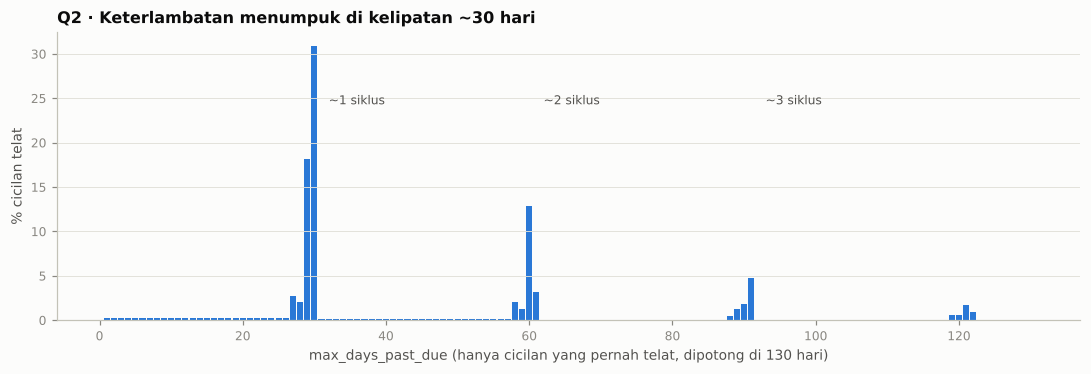

Porsi cicilan telat per rentang hari:
    1–27   :   8.2%
   28–31   :  51.2%
   32–57   :   2.4%
   58–62   :  19.4%
   63–87   :   1.2%
   88–92   :   8.2%
   93–∞    :   9.3%

Porsi cicilan yang pernah telat: 33.8%
Bayar sebagian: 27,069 cicilan, median porsi terbayar 53%


In [4]:
late = rh.filter(pl.col("max_days_past_due") > 0)
cnt = late.filter(pl.col("max_days_past_due") <= 130).group_by("max_days_past_due").agg(n=pl.len()).sort("max_days_past_due")
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(cnt["max_days_past_due"].to_numpy(), cnt["n"].to_numpy() / late.height * 100, color=E.C_RATE, width=0.85)
for x, lab in [(30, "~1 siklus"), (60, "~2 siklus"), (91, "~3 siklus")]:
    ax.annotate(lab, (x, 0), xytext=(x + 2, ax.get_ylim()[1] * 0.75), fontsize=8, color=E.INK2)
ax.set_xlabel("max_days_past_due (hanya cicilan yang pernah telat, dipotong di 130 hari)")
ax.set_ylabel("% cicilan telat")
ax.set_title("Q2 · Keterlambatan menumpuk di kelipatan ~30 hari")
plt.show()

buckets = [(1, 27), (28, 31), (32, 57), (58, 62), (63, 87), (88, 92), (93, 10_000)]
v = late["max_days_past_due"]
print("Porsi cicilan telat per rentang hari:")
for lo, hi in buckets:
    print(f"  {lo:>3}–{hi if hi < 10_000 else '∞':<5}: {((v >= lo) & (v <= hi)).mean():6.1%}")
print(f"\nPorsi cicilan yang pernah telat: {(rh['max_days_past_due'] > 0).mean():.1%}")
part = rh.filter((pl.col("amount_paid") > 0) & (pl.col("amount_paid") < pl.col("amount_due")))
print(f"Bayar sebagian: {part.height:,} cicilan, median porsi terbayar {(part['amount_paid'] / part['amount_due']).median():.0%}")

**Jawaban Q2 — "telat" di sini berarti melewatkan satu atau lebih siklus tagihan penuh.**
- ~51% keterlambatan berada di 28–31 hari, ~19% di 58–62 hari, ~8% di 88–92 hari. Keterlambatan kecil (1–27 hari) hanya ~8%.
- Polanya: nasabah tidak membayar bulan ini, lalu melunasi bersamaan dengan tagihan bulan berikutnya (atau beberapa bulan kemudian).
- Sekitar **34% cicilan pernah telat**. Ini angka yang besar, jadi "pernah telat sekali" tidak otomatis buruk; yang membedakan adalah **seberapa sering**.

**Implikasi fitur**: ambang 30/60/90 hari tidak sembarang, karena setara dengan 1/2/3 siklus terlewat. Fitur **frekuensi** (porsi cicilan telat, jumlah siklus terlewat) kemungkinan lebih informatif daripada keparahan maksimum. Ini diuji di Q5.

## Q3 · Pola pengajuan

Dianalisis pada nasabah yang **punya** pengajuan lama, karena untuk segmen A semua fitur ini null.

Noise floor subset punya pengajuan: 0.0165 | subset punya cicilan: 0.0180


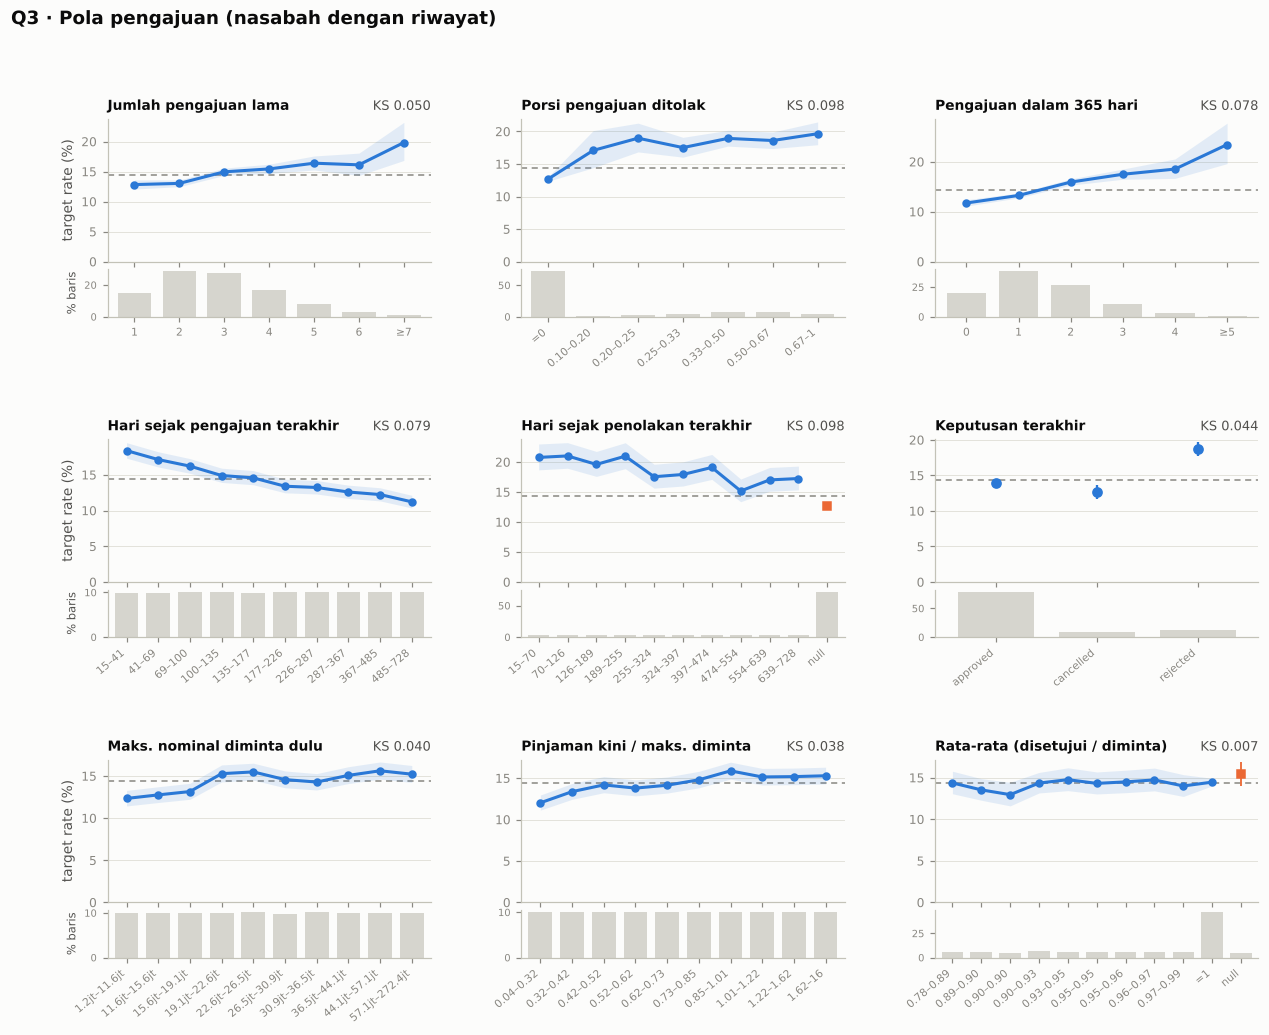

feature,null_pct,ks,auc,arah,iv,ks_x_noise
str,f64,f64,f64,str,f64,f64
"""pa_mean_rate""",4.97,0.1832,0.6326,"""↑ nilai → ↑ risiko""",0.2242,11.1
"""pa_last_rate""",4.97,0.1787,0.6201,"""↑ nilai → ↑ risiko""",0.1997,10.8
"""pa_max_rate""",4.97,0.1611,0.615,"""↑ nilai → ↑ risiko""",0.1891,9.8
"""pa_reject_share""",0.0,0.0981,0.5497,"""↑ nilai → ↑ risiko""",0.045,6.0
"""pa_days_since_last_reject""",71.73,0.0977,0.4715,"""↑ nilai → ↓ risiko""",0.0493,5.9
"""pa_n_rejected""",0.0,0.0975,0.5524,"""↑ nilai → ↑ risiko""",0.0552,5.9
"""pa_days_since_last""",0.0,0.0785,0.4497,"""↑ nilai → ↓ risiko""",0.0307,4.8
"""pa_n_365d""",0.0,0.0781,0.5477,"""↑ nilai → ↑ risiko""",0.0309,4.7
"""pa_n_180d""",0.0,0.0759,0.5469,"""↑ nilai → ↑ risiko""",0.0342,4.6


In [5]:
NOISE_H = E.ks_noise_floor(hist["target"].to_numpy(), n_perm=200)
NOISE_R = E.ks_noise_floor(rep["target"].to_numpy(), n_perm=200)
print(f"Noise floor subset punya pengajuan: {NOISE_H:.4f} | subset punya cicilan: {NOISE_R:.4f}")
E.plot_rates(hist, ["pa_n", "pa_reject_share", "pa_n_365d", "pa_days_since_last", "pa_days_since_last_reject", "pa_last_decision",
                    "pa_max_requested", "amount_vs_max_requested", "pa_mean_cut_ratio"],
             titles={"pa_n": "Jumlah pengajuan lama", "pa_reject_share": "Porsi pengajuan ditolak",
                     "pa_n_365d": "Pengajuan dalam 365 hari", "pa_days_since_last": "Hari sejak pengajuan terakhir",
                     "pa_days_since_last_reject": "Hari sejak penolakan terakhir", "pa_last_decision": "Keputusan terakhir",
                     "pa_max_requested": "Maks. nominal diminta dulu",
                     "amount_vs_max_requested": "Pinjaman kini / maks. diminta",
                     "pa_mean_cut_ratio": "Rata-rata (disetujui / diminta)"},
             suptitle="Q3 · Pola pengajuan (nasabah dengan riwayat)")
sig_pa = E.signal_table(hist, PA).with_columns((pl.col("ks") / NOISE_H).round(1).alias("ks_x_noise"))
sig_pa.select("feature", "null_pct", "ks", "auc", "arah", "iv", "ks_x_noise")

**Jawaban Q3 — pola pengajuan hanya sinyal sedang, kecuali suku bunga lama.**
- Penanda terkuat di kelompok `pa_*` adalah **suku bunga pinjaman lama** (`pa_mean_rate` / `pa_last_rate`, KS ~0,18). Ini penilaian risiko lender **di masa lalu**, dan akan dibahas lebih jauh di Q4 & Q8.
- **Penolakan** (`pa_reject_share`, `pa_n_rejected`, KS ~0,10) dan **frekuensi pengajuan** (`pa_n_365d`, `pa_days_since_last`, KS ~0,08) punya arah yang masuk akal: makin sering ditolak dan makin "lapar kredit", makin berisiko.
- **Pembatalan** dan rasio **disetujui/diminta** hampir noise. Pemotongan plafon bukan sinyal risiko di data ini.
- Jumlah pengajuan total (`pa_n`, KS 0,05) jauh lebih lemah daripada komposisinya (berapa yang ditolak).

## Q4 · Pinjaman lama: beban berjalan & suku bunga masa lalu

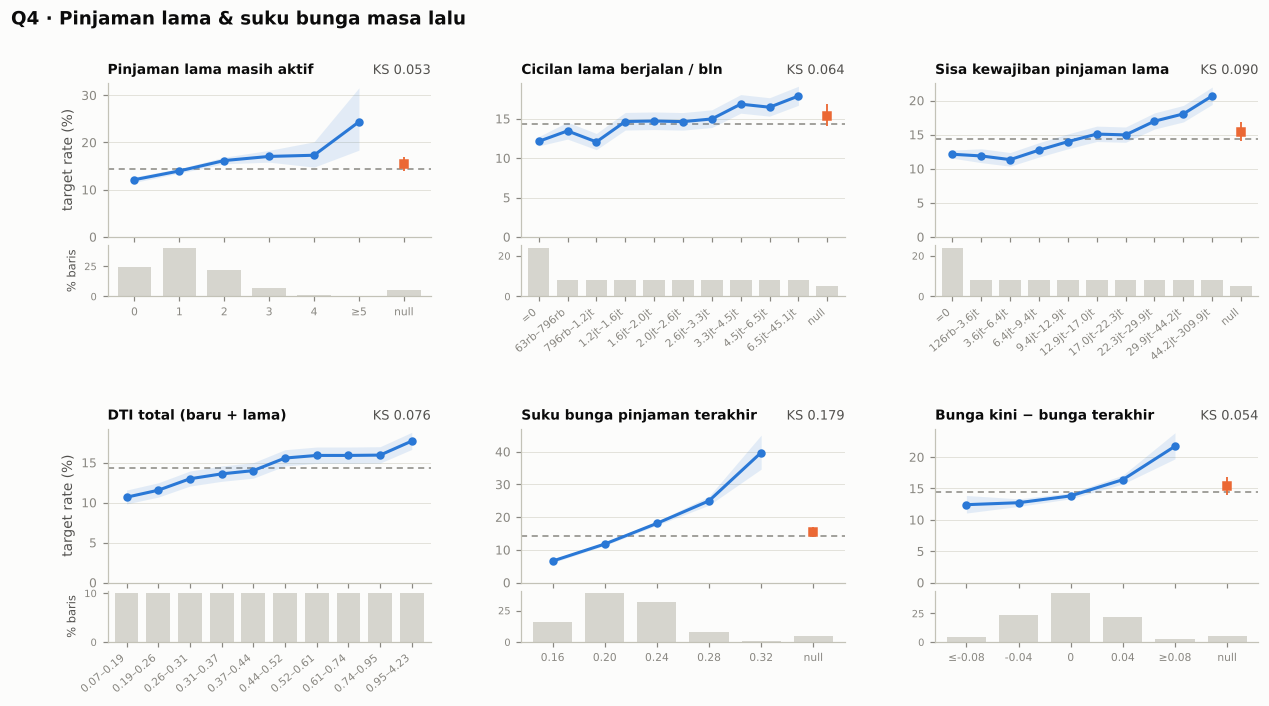

feature,null_pct,ks,auc,arah,ks_x_noise
str,f64,f64,f64,str,f64
"""pa_last_rate""",4.97,0.1787,0.6201,"""↑ nilai → ↑ risiko""",10.8
"""ln_remaining_amount""",4.97,0.0898,0.5591,"""↑ nilai → ↑ risiko""",5.4
"""dti""",0.0,0.0775,0.5491,"""↑ nilai → ↑ risiko""",4.7
"""total_dti""",0.0,0.0763,0.5483,"""↑ nilai → ↑ risiko""",4.6
"""ln_active_installment""",4.97,0.0636,0.543,"""↑ nilai → ↑ risiko""",3.9
"""ln_days_since_last_loan""",4.97,0.0625,0.4594,"""↑ nilai → ↓ risiko""",3.8
"""rate_change_vs_last""",4.97,0.0536,0.5367,"""↑ nilai → ↑ risiko""",3.3
"""ln_n_active""",4.97,0.0531,0.538,"""↑ nilai → ↑ risiko""",3.2
"""ln_total_approved""",4.97,0.0165,0.5109,"""↑ nilai → ↑ risiko""",1.0


In [6]:
E.plot_rates(hist, ["ln_n_active", "ln_active_installment", "ln_remaining_amount", "total_dti", "pa_last_rate", "rate_change_vs_last"],
             titles={"ln_n_active": "Pinjaman lama masih aktif", "ln_active_installment": "Cicilan lama berjalan / bln",
                     "ln_remaining_amount": "Sisa kewajiban pinjaman lama", "total_dti": "DTI total (baru + lama)",
                     "pa_last_rate": "Suku bunga pinjaman terakhir", "rate_change_vs_last": "Bunga kini − bunga terakhir"},
             suptitle="Q4 · Pinjaman lama & suku bunga masa lalu")
E.signal_table(hist, LN + ["dti", "pa_last_rate", "rate_change_vs_last"]).with_columns(
    (pl.col("ks") / NOISE_H).round(1).alias("ks_x_noise")).select("feature", "null_pct", "ks", "auc", "arah", "ks_x_noise")

**Jawaban Q4.**
- **Suku bunga pinjaman lama** naik → risiko naik tajam (KS ~0,18). Nasabah yang **bunganya naik** dibanding pinjaman terakhir (`rate_change_vs_last` > 0) juga lebih berisiko; artinya lender pernah "menurunkan rating" mereka.
- **Beban berjalan** (`ln_remaining_amount`, `ln_active_installment`) memberi sinyal sedang (KS 0,06–0,09). Secara univariat, **DTI total** (cicilan baru + cicilan lama yang masih berjalan) setara dengan DTI pinjaman ini saja (0,076 vs 0,078). Namun di Q8 terlihat bahwa DTI total membawa **jauh lebih banyak info di luar suku bunga**, begitu juga sisa kewajiban pinjaman lama.
- Jumlah pinjaman lama atau total nominal yang pernah disetujui hampir tidak informatif. Yang penting adalah **beban saat ini**, bukan sejarah volumenya.

## Q5 · Perilaku bayar

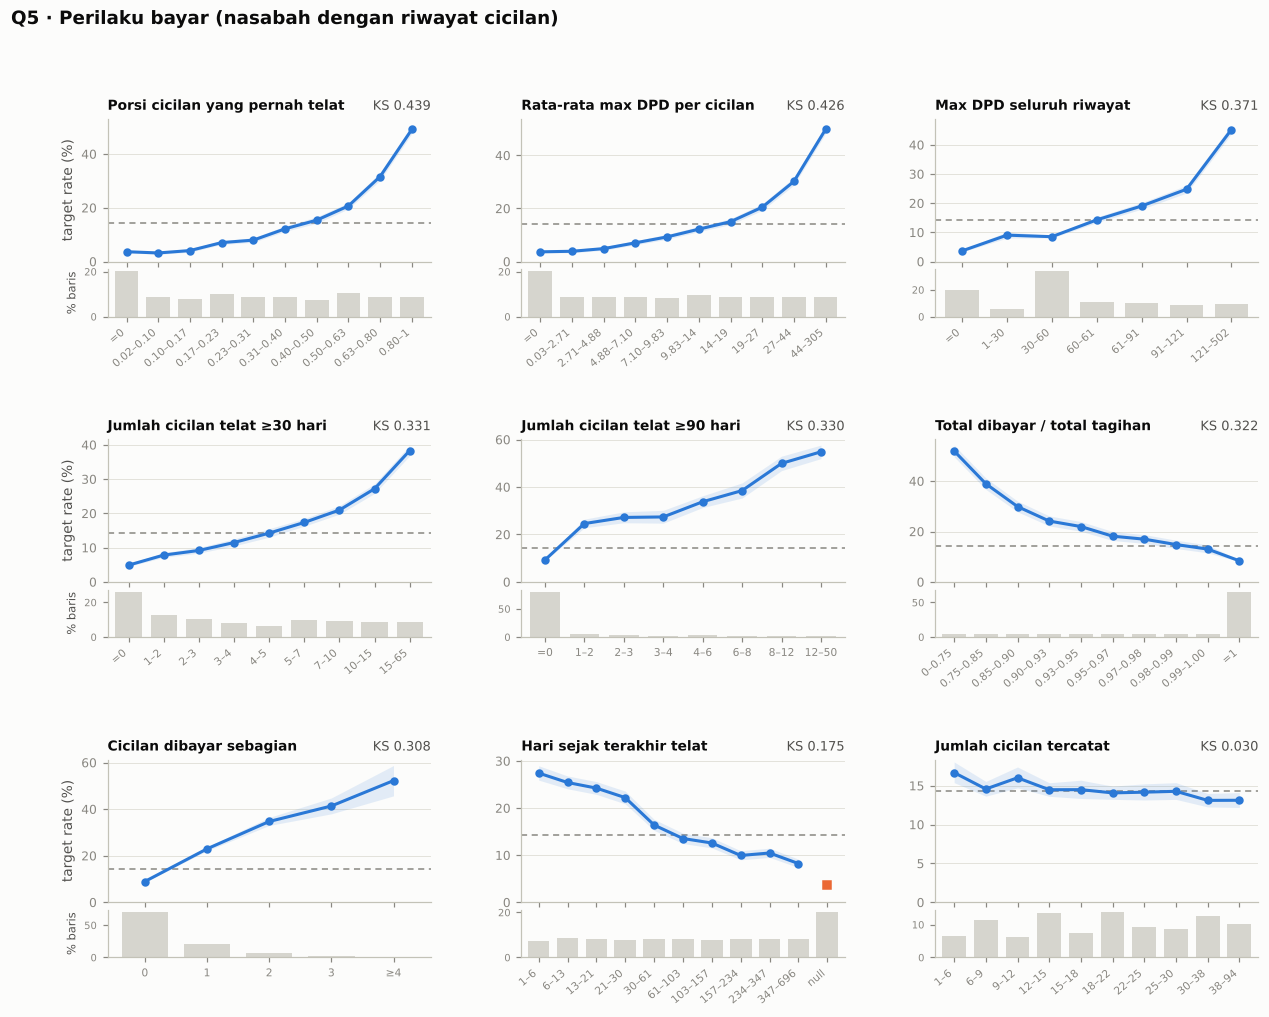

feature,null_pct,ks,auc,arah,iv,ks_x_noise
str,f64,f64,f64,str,f64,f64
"""rp_late_share""",0.0,0.4391,0.784,"""↑ nilai → ↑ risiko""",1.1499,24.4
"""rp_mean_dpd""",0.0,0.4265,0.779,"""↑ nilai → ↑ risiko""",1.0928,23.7
"""rp_late_share_365d""",2.42,0.4241,0.7723,"""↑ nilai → ↑ risiko""",1.0215,23.5
"""rp_max_dpd_ever""",0.0,0.3709,0.7443,"""↑ nilai → ↑ risiko""",0.8205,20.6
"""rp_max_dpd_365d""",2.42,0.3697,0.7426,"""↑ nilai → ↑ risiko""",0.7955,20.5
"""rp_late_share_180d""",9.61,0.3684,0.7495,"""↑ nilai → ↑ risiko""",0.7862,20.4
"""rp_n_dpd60""",0.0,0.3596,0.7184,"""↑ nilai → ↑ risiko""",0.7084,19.9
"""rp_max_dpd_180d""",9.61,0.3357,0.7346,"""↑ nilai → ↑ risiko""",0.7038,18.6
"""rp_n_dpd30""",0.0,0.3309,0.7181,"""↑ nilai → ↑ risiko""",0.629,18.4


In [7]:
E.plot_rates(rep, ["rp_late_share", "rp_mean_dpd", "rp_max_dpd_ever", "rp_n_dpd30", "rp_n_dpd90", "rp_paid_ratio",
                   "rp_n_partial", "rp_days_since_last_late", "rp_n_inst"],
             titles={"rp_late_share": "Porsi cicilan yang pernah telat", "rp_mean_dpd": "Rata-rata max DPD per cicilan",
                     "rp_max_dpd_ever": "Max DPD seluruh riwayat", "rp_n_dpd30": "Jumlah cicilan telat ≥30 hari",
                     "rp_n_dpd90": "Jumlah cicilan telat ≥90 hari", "rp_paid_ratio": "Total dibayar / total tagihan",
                     "rp_n_partial": "Cicilan dibayar sebagian", "rp_days_since_last_late": "Hari sejak terakhir telat",
                     "rp_n_inst": "Jumlah cicilan tercatat"},
             suptitle="Q5 · Perilaku bayar (nasabah dengan riwayat cicilan)")
sig_rp = E.signal_table(rep, RP).with_columns((pl.col("ks") / NOISE_R).round(1).alias("ks_x_noise"))
sig_rp.select("feature", "null_pct", "ks", "auc", "arah", "iv", "ks_x_noise")

**Jawaban Q5 — perilaku bayar adalah sinyal TERKUAT sejauh ini, hampir 2× suku bunga.**
- **`rp_late_share`** (porsi cicilan yang pernah telat) mencapai **KS ≈ 0,44** seorang diri pada nasabah dengan riwayat cicilan. Default rate naik dari ~3–4% (tidak pernah telat, atau telat di < 17% cicilan) menjadi ~49% (telat di > 80% cicilan), sebuah gradien yang sangat bersih dan monoton.
- **Frekuensi > keparahan**: `rp_late_share` (0,44) dan `rp_mean_dpd` (0,43) lebih kuat daripada `rp_max_dpd_ever` (0,37) maupun jumlah cicilan ≥90 hari (0,33). Sesuai dugaan Q2, yang membedakan adalah *kebiasaan* telat, bukan satu insiden parah.
- `rp_paid_ratio` (porsi tagihan yang dibayar) dan pembayaran sebagian juga kuat (~0,31–0,32). Nasabah yang membayar 100% tagihannya hanya ~8% default.
- `rp_n_inst` sendiri hampir tidak informatif, tetapi menentukan **seberapa andal** porsi telat tersebut (lihat Q7).

## Q6 · Tunggakan aktif saat keputusan

`days_past_due` pada cicilan yang belum lunas = umur tunggakan **saat cutoff**. Ini kondisi nasabah *pada hari keputusan*.

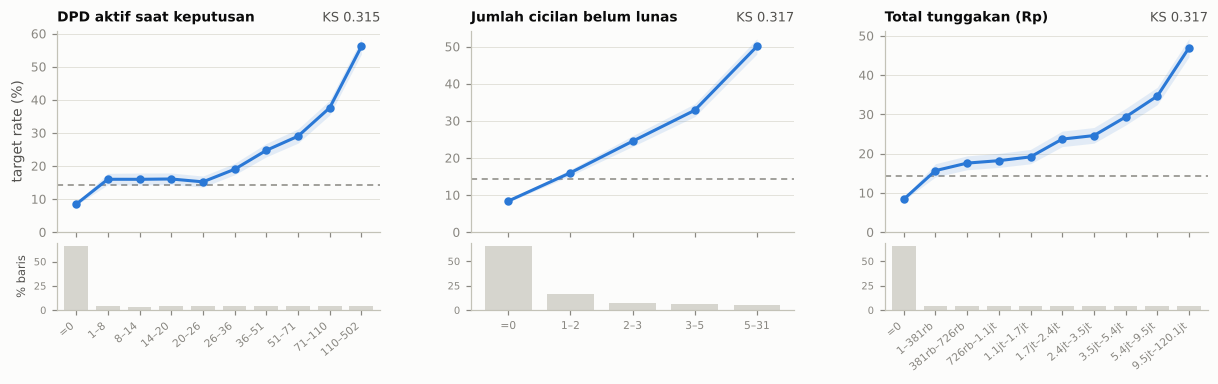

active_delinquency,n,target_rate
bool,u32,f64
false,30288,0.0838
true,16024,0.2554


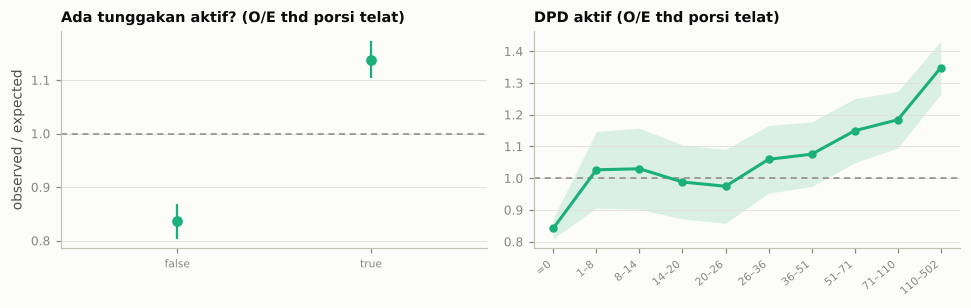

In [8]:
E.plot_rates(rep, ["rp_current_dpd", "rp_n_unpaid_now", "rp_overdue_amount"],
             titles={"rp_current_dpd": "DPD aktif saat keputusan", "rp_n_unpaid_now": "Jumlah cicilan belum lunas",
                     "rp_overdue_amount": "Total tunggakan (Rp)"}, ncols=3)
act = rep.with_columns(active_delinquency=pl.col("rp_n_unpaid_now") > 0)
display(act.group_by("active_delinquency").agg(n=pl.len(), target_rate=pl.col("target").mean().round(4)).sort("active_delinquency"))
# apakah tunggakan aktif menambah info di atas porsi telat historis?
act = act.with_columns(exp_by_late=pl.col("target").mean().over(pl.col("rp_late_share").qcut(10, allow_duplicates=True)))
E.plot_oe(act, ["active_delinquency", "rp_current_dpd"], expected="exp_by_late", ncols=2, width=9,
          titles={"active_delinquency": "Ada tunggakan aktif? (O/E thd porsi telat)", "rp_current_dpd": "DPD aktif (O/E thd porsi telat)"})

**Jawaban Q6.**
- Sekitar sepertiga nasabah ber-riwayat **sedang menunggak** saat keputusan, dan default rate mereka **~25,5% vs ~8,4%** untuk yang tidak.
- Gradiennya tajam: tanpa tunggakan ~8,5%; tunggakan 1–36 hari ~15–19%; > 110 hari ~56%.
- Grafik O/E (setelah porsi telat historis diperhitungkan) lebih bernuansa:
  - **Tidak sedang menunggak** → ~0,84× ekspektasi, jadi lebih aman daripada yang diprediksi kebiasaan telatnya.
  - **Tunggakan pendek (1–26 hari)** → O/E ≈ 1,0. Default rate mentahnya memang ~16% (2× nasabah lancar), tapi itu sudah dijelaskan oleh kebiasaan telatnya; tidak ada info tambahan.
  - **Tunggakan panjang (> 36 hari)** → 1,08–1,35×. Di sinilah informasi tambahannya.
- Implikasi: selain DPD aktif mentah, buat flag **"lancar saat keputusan"** dan **"tunggakan ≥ 30/60 hari"**; tunggakan pendek tidak perlu diperlakukan khusus.

## Q7 · Jendela waktu & keandalan fitur

Tiga pertanyaan: (a) apakah perilaku **terbaru** lebih informatif daripada **seluruh riwayat**? (b) apakah porsi telat dari riwayat **pendek** bisa dipercaya? (c) apakah **arah perubahan** (membaik/memburuk) penting?

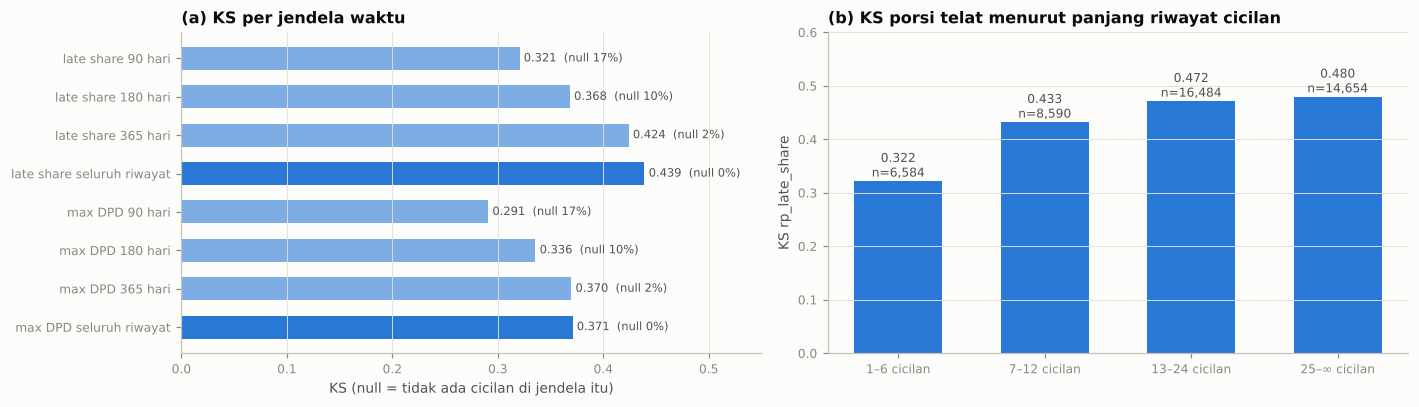

In [9]:
y_rep = rep["target"].to_numpy()
win = [("late share 90 hari", "rp_late_share_90d"), ("late share 180 hari", "rp_late_share_180d"),
       ("late share 365 hari", "rp_late_share_365d"), ("late share seluruh riwayat", "rp_late_share"),
       ("max DPD 90 hari", "rp_max_dpd_90d"), ("max DPD 180 hari", "rp_max_dpd_180d"),
       ("max DPD 365 hari", "rp_max_dpd_365d"), ("max DPD seluruh riwayat", "rp_max_dpd_ever")]
win_ks = [(lab, E.ks_stat(y_rep, rep[c].to_numpy()), rep[c].is_null().mean()) for lab, c in win]

groups = [(0, 6), (6, 12), (12, 24), (24, 999)]
rel = []
for lo, hi in groups:
    s = rep.filter((pl.col("rp_n_inst") > lo) & (pl.col("rp_n_inst") <= hi))
    rel.append((f"{lo+1}–{hi if hi < 999 else '∞'} cicilan", E.ks_stat(s["target"].to_numpy(), s["rp_late_share"].to_numpy()), s.height))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
labs = [w[0] for w in win_ks][::-1]
ax.barh(labs, [w[1] for w in win_ks][::-1], color=[E.C_RATE if "seluruh" in l else E.SERIES[0] + "99" for l in labs], height=0.6)
for i, (l, k, nn) in enumerate(win_ks[::-1]):
    ax.text(k + 0.004, i, f"{k:.3f}  (null {nn:.0%})", va="center", fontsize=7.5, color=E.INK2)
ax.set_xlim(0, 0.55); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("(a) KS per jendela waktu"); ax.set_xlabel("KS (null = tidak ada cicilan di jendela itu)")
ax = axes[1]
ax.bar([r[0] for r in rel], [r[1] for r in rel], color=E.C_RATE, width=0.6)
for i, r in enumerate(rel):
    ax.text(i, r[1] + 0.008, f"{r[1]:.3f}\nn={r[2]:,}", ha="center", fontsize=8, color=E.INK2)
ax.set_ylim(0, 0.6)
ax.set_title("(b) KS porsi telat menurut panjang riwayat cicilan"); ax.set_ylabel("KS rp_late_share")
plt.tight_layout(); plt.show()

37,417 nasabah punya cicilan < 180 hari DAN ≥ 180 hari sebelum cutoff
  KS late share 180 hari terakhir : 0.413
  KS late share sebelum 180 hari  : 0.412
  KS late share gabungan          : 0.463


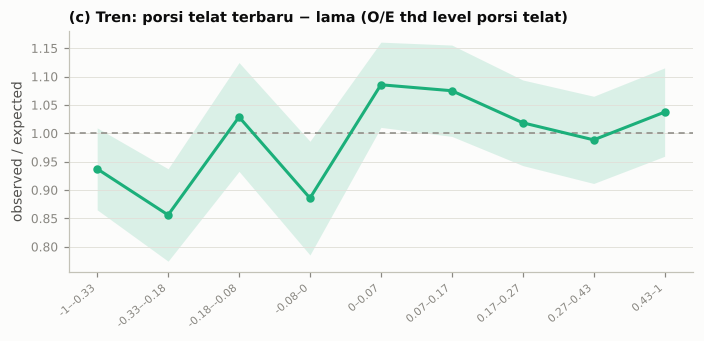

In [10]:
# (c) membaik vs memburuk: porsi telat 180 hari terakhir vs sebelumnya, pada nasabah yang punya keduanya
r = rh.join(CUT, on="customer_id", how="inner").with_columns(
    age_d=days_between(pl.col("cutoff"), pl.col("due_date")), late=pl.col("max_days_past_due") > 0)
tr_ = (r.group_by("customer_id")
        .agg(late_recent=pl.col("late").filter(pl.col("age_d") < 180).mean(),
             late_older=pl.col("late").filter(pl.col("age_d") >= 180).mean(),
             late_all=pl.col("late").mean())
        .drop_nulls(["late_recent", "late_older"])
        .join(tr.select("customer_id", "target"), on="customer_id")
        .with_columns(trend=pl.col("late_recent") - pl.col("late_older"))
        .with_columns(exp_by_level=pl.col("target").mean().over(pl.col("late_all").qcut(10, allow_duplicates=True))))
yt = tr_["target"].to_numpy()
print(f"{tr_.height:,} nasabah punya cicilan < 180 hari DAN ≥ 180 hari sebelum cutoff")
print(f"  KS late share 180 hari terakhir : {E.ks_stat(yt, tr_['late_recent'].to_numpy()):.3f}")
print(f"  KS late share sebelum 180 hari  : {E.ks_stat(yt, tr_['late_older'].to_numpy()):.3f}")
print(f"  KS late share gabungan          : {E.ks_stat(yt, tr_['late_all'].to_numpy()):.3f}")
E.plot_oe(tr_, ["trend"], expected="exp_by_level", ncols=1, width=6.5, row_h=3.2,
          titles={"trend": "(c) Tren: porsi telat terbaru − lama (O/E thd level porsi telat)"})

**Jawaban Q7.**
- **(a) Seluruh riwayat menang.** Porsi telat sepanjang riwayat (KS ~0,44) > 365 hari > 180 hari > 90 hari. Pada nasabah yang punya data di kedua periode, porsi telat 180 hari terakhir dan porsi telat sebelumnya **sama kuatnya** (~0,41), sedangkan gabungannya jauh lebih kuat (~0,46). Artinya kebiasaan bayar adalah **sifat yang stabil**: makin banyak cicilan yang diamati, makin akurat estimasinya. Jendela pendek hanya membuang data.
- **(b) Keandalan bergantung pada jumlah cicilan.** KS porsi telat hanya ~0,32 bila cicilannya ≤ 6, tapi ~0,48 bila > 24. Porsi telat 1 dari 2 cicilan jauh kurang meyakinkan daripada 12 dari 24. Saya juga mencoba *Bayesian smoothing* (menarik porsi telat ke rata-rata populasi), tapi hasilnya hampir tidak berubah (±0,001). Cukup sertakan `rp_n_inst` bersama porsi telat agar GBDT bisa menimbang sendiri.
- **(c) Tren punya efek kecil dan kurang stabil.** Pada level porsi telat yang sama, nasabah yang **membaik** umumnya ~0,86–0,94× dari ekspektasi (satu bin ~1,03), sedangkan yang **memburuk** ~0,99–1,09×. Polanya bergerigi dan intervalnya lebar. Boleh menjadi fitur tambahan, tapi bukan prioritas.

## Q8 · Apakah suku bunga sudah memperhitungkan riwayat bayar?

Kalau lender menentukan bunga berdasarkan riwayat bayar, maka sinyal riwayat akan "tumpang tindih" dengan bunga dan nilai tambahnya kecil. Kita uji.

annual_interest_rate,n,mean_late_share,median_max_dpd,mean_prev_rate,mean_reject_share,target_rate
f64,u32,f64,f64,f64,f64,f64
0.16,8356,0.208,30.0,0.188,0.04,0.053
0.2,19444,0.287,30.0,0.209,0.078,0.11
0.24,14802,0.379,54.0,0.227,0.124,0.187
0.28,3446,0.523,61.0,0.247,0.185,0.328
0.32,264,0.723,150.0,0.265,0.23,0.53


Spearman suku bunga sekarang vs porsi telat: 0.277 | vs suku bunga terakhir: 0.468


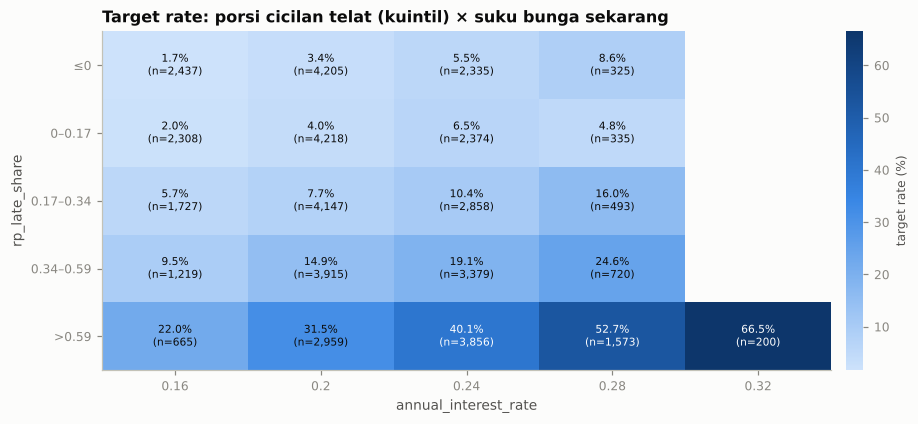

In [11]:
display(rep.group_by("annual_interest_rate")
           .agg(n=pl.len(), mean_late_share=pl.col("rp_late_share").mean(), median_max_dpd=pl.col("rp_max_dpd_ever").median(),
                mean_prev_rate=pl.col("pa_last_rate").mean(), mean_reject_share=pl.col("pa_reject_share").mean(),
                target_rate=pl.col("target").mean())
           .with_columns(pl.col(pl.Float64).round(3)).sort("annual_interest_rate"))
print("Spearman suku bunga sekarang vs porsi telat:", round(rep.select(pl.corr("annual_interest_rate", "rp_late_share", method="spearman")).item(), 3),
      "| vs suku bunga terakhir:", round(rep.select(pl.corr("annual_interest_rate", "pa_last_rate", method="spearman")).item(), 3))
E.heatmap_rate(rep, "rp_late_share", "annual_interest_rate", row_bins=5,
               title="Target rate: porsi cicilan telat (kuintil) × suku bunga sekarang", figsize=(9, 4))

In [12]:
rows = []
for f in ["rp_late_share", "rp_mean_dpd", "rp_max_dpd_ever", "rp_current_dpd", "rp_paid_ratio",
          "pa_last_rate", "rate_change_vs_last", "pa_reject_share", "pa_n_365d", "total_dti", "ln_remaining_amount", "dti"]:
    sub = rep if f.startswith("rp_") else hist
    s, _ = E.ks_within(sub, f, "annual_interest_rate", n_perm=30)
    rows.append(s)
(pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))
   .with_columns(pl.when(pl.col("excess_within") > 0.005).then(pl.lit("✅ info di luar bunga"))
                   .otherwise(pl.lit("— sudah tercakup bunga")).alias("verdict"))
   .sort("excess_within", descending=True))

feature,ks_overall,ks_within,noise_within,excess_within,verdict
str,f64,f64,f64,f64,str
"""rp_late_share""",0.4391,0.3978,0.0365,0.3613,"""✅ info di luar bunga"""
"""rp_mean_dpd""",0.4265,0.385,0.0365,0.3485,"""✅ info di luar bunga"""
"""rp_max_dpd_ever""",0.3709,0.3296,0.0365,0.293,"""✅ info di luar bunga"""
"""rp_paid_ratio""",0.322,0.2692,0.0365,0.2327,"""✅ info di luar bunga"""
"""rp_current_dpd""",0.3151,0.2606,0.0365,0.2241,"""✅ info di luar bunga"""
"""ln_remaining_amount""",0.0898,0.1114,0.0331,0.0783,"""✅ info di luar bunga"""
"""pa_last_rate""",0.1787,0.0853,0.0331,0.0521,"""✅ info di luar bunga"""
"""rate_change_vs_last""",0.0536,0.0828,0.0331,0.0497,"""✅ info di luar bunga"""
"""total_dti""",0.0763,0.0741,0.0331,0.041,"""✅ info di luar bunga"""


**Jawaban Q8 — bunga hanya menangkap SEBAGIAN kecil riwayat bayar.**
- Lender memang memakai riwayat: rata-rata porsi telat naik dari ~0,21 (bunga 16%) ke ~0,72 (bunga 32%), dan bunga sekarang berkorelasi dengan bunga lama (ρ ≈ 0,47). Tapi korelasi bunga dengan porsi telat hanya ρ ≈ 0,28.
- **Di dalam setiap kelompok bunga**, porsi telat masih punya KS ~0,40 (noise ~0,035). Heatmap memperlihatkannya dengan jelas: pada bunga 24% yang sama, default rate berkisar dari ~5,5% (porsi telat 0) sampai ~40% (porsi telat > 0,59). Bahkan nasabah dengan porsi telat rendah di bunga **28%** (~5–9%) lebih aman daripada nasabah dengan porsi telat tinggi di bunga **16%** (~22%).
- Fitur repayment (`rp_late_share`, `rp_mean_dpd`, `rp_max_dpd_ever`, `rp_paid_ratio`, `rp_current_dpd`) membawa **informasi besar di luar bunga**.
- Info tambahan sedang datang dari `ln_remaining_amount` (sisa kewajiban; KS-nya di dalam kelompok bunga justru lebih tinggi daripada keseluruhan), `pa_last_rate`, `rate_change_vs_last`, `total_dti`, dan frekuensi pengajuan `pa_n_365d`. Hanya **porsi penolakan** yang sudah tercakup bunga.

➡️ Ini jawaban parsial untuk pertanyaan terbuka Bagian 1 ("apa yang menentukan bunga?"): riwayat internal **ikut** menentukan bunga, tapi dengan bobot yang jauh lebih kecil daripada kekuatan prediktifnya. Faktor lain kemungkinan dari biro (Bagian 3).

## Q9 · Kontribusi riwayat internal terhadap KS

LightGBM 5-fold OOF pada **seluruh train** (nasabah tanpa riwayat → fitur null). Patokan dari Bagian 1 adalah ~0,23.

config,n_features,ks_oof,auc_oof
str,i64,f64,f64
"""1. patokan (aplikasi + profil)""",12,0.228,0.6455
"""2. + pengajuan lama (pa_*)""",35,0.2444,0.6698
"""3. + pinjaman berjalan (ln_*)""",42,0.2493,0.6743
"""4. patokan + repayment (rp_*) saja""",31,0.3884,0.7679
"""5. semua riwayat internal + segmen""",62,0.398,0.7756


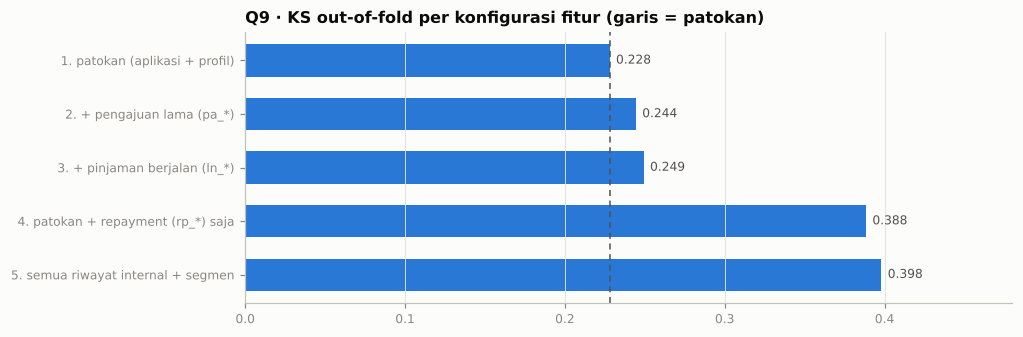

In [13]:
CATS = ["loan_purpose", "region", "employment_type", "housing_status", "pa_last_decision", "segment"]
BASE = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose", "age", "region",
        "employment_type", "employment_tenure_months", "declared_monthly_income", "dependents", "housing_status", "dti"]
configs = {
    "1. patokan (aplikasi + profil)": BASE,
    "2. + pengajuan lama (pa_*)": BASE + PA,
    "3. + pinjaman berjalan (ln_*)": BASE + PA + LN,
    "4. patokan + repayment (rp_*) saja": BASE + RP,
    "5. semua riwayat internal + segmen": BASE + PA + LN + RP + ["segment"],
}
res, oofs, imps = [], {}, {}
for name, feats in configs.items():
    oof, ks, auc, imp = E.cv_lgb(df, feats, cat_features=[c for c in CATS if c in feats])
    res.append(dict(config=name, n_features=len(feats), ks_oof=round(ks, 4), auc_oof=round(auc, 4)))
    oofs[name], imps[name] = oof, imp
res = pl.DataFrame(res)
display(res)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(res["config"].to_list()[::-1], res["ks_oof"].to_list()[::-1], color=E.C_RATE, height=0.6)
for i, v in enumerate(res["ks_oof"].to_list()[::-1]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=E.INK2)
ax.axvline(res["ks_oof"][0], color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.set_xlim(0, 0.48); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Q9 · KS out-of-fold per konfigurasi fitur (garis = patokan)")
plt.show()

In [14]:
last = list(configs)[-1]
scored = df.select("segment", "target").with_columns(oof=pl.Series(oofs[last]))
seg_ks = pl.DataFrame([dict(segment=k[0], n=g.height, target_rate=round(g["target"].mean(), 4),
                            ks=round(E.ks_stat(g["target"].to_numpy(), g["oof"].to_numpy()), 4))
                       for k, g in scored.group_by("segment")]).sort("segment")
display(seg_ks)
imps[last].head(20).with_columns(pl.col("gain_pct").round(2))

segment,n,target_rate,ks
str,i64,f64,f64
"""A. tanpa riwayat""",21000,0.1172,0.1981
"""B. ada pengajuan, belum ada cicilan""",2688,0.1551,0.1984
"""C. ada riwayat cicilan""",46312,0.1431,0.4924


feature,gain_pct
str,f64
"""rp_late_share""",36.8
"""rp_mean_dpd""",10.89
"""annual_interest_rate""",6.52
"""ln_remaining_amount""",4.89
"""rp_late_share_365d""",4.48
"""rp_paid_ratio""",3.33
"""amount_vs_max_requested""",3.12
"""rp_n_inst""",3.04
"""ln_total_approved""",2.26


**Jawaban Q9 — riwayat internal mendorong KS dari ~0,23 menjadi ~0,40.**
- Pengajuan lama (+~0,016) dan pinjaman berjalan (+~0,006) memberi kenaikan kecil. **Repayment saja** langsung membawa KS ke ~0,39.
- Importance didominasi `rp_late_share` dan `rp_mean_dpd`. Suku bunga turun ke posisi ketiga: model kini punya sumber yang lebih langsung.
- **Per segmen**: KS ~0,49 pada nasabah dengan riwayat cicilan, tapi hanya ~0,19 pada nasabah tanpa riwayat (dan segmen B), yang masih bergantung pada suku bunga + profil saja. Jadi **30% nasabah tanpa riwayat adalah titik lemah model**. Biro (Bagian 3), rekening, dan e-commerce (Bagian 4–5) harus dinilai terutama dari kemampuannya mengangkat segmen ini.
- Catatan: KS keseluruhan bukan rata-rata KS per segmen. Ia juga bergantung pada seberapa baik skor kedua segmen "sejajar" dalam satu urutan.

## Ringkasan Bagian 2

| Temuan | Implikasi untuk feature engineering |
|---|---|
| Tiga segmen: tanpa riwayat (30%), pengajuan tanpa cicilan (~4%, paling berisiko), riwayat cicilan (66%) | Tambahkan **flag segmen** eksplisit; null di `rp_*` punya dua arti |
| "Telat" = melewatkan siklus penuh (~30/60/90 hari) | Ambang 30/60/90 bermakna; hitung **jumlah siklus terlewat** |
| **Porsi cicilan telat** = fitur terkuat (KS ~0,44), frekuensi > keparahan | Prioritas utama: porsi telat, rata-rata DPD, porsi tagihan terbayar |
| Seluruh riwayat > jendela pendek; perilaku stabil | Pakai agregat **seluruh riwayat** sebagai inti; jendela pendek opsional |
| Keandalan porsi telat naik dengan jumlah cicilan | Selalu sertakan `rp_n_inst`; smoothing tidak perlu |
| Tunggakan aktif menambah info di atas kebiasaan telat, tapi hanya di dua ujung (lancar vs > 36 hari) | DPD aktif, flag lancar, flag tunggakan ≥ 30/60 hari, total tunggakan |
| Tren membaik/memburuk berefek kecil | Fitur tambahan opsional (porsi telat terbaru − lama) |
| Suku bunga lama & perubahan bunga informatif | `pa_last_rate`, `rate_change_vs_last` |
| Frekuensi pengajuan & sisa kewajiban punya info di luar bunga; porsi penolakan sudah tercakup | Masukkan `pa_n_365d`, `ln_remaining_amount`; penolakan prioritas rendah |
| DTI total (baru + lama) > DTI pinjaman ini saja | Gunakan beban **total**; nanti diperluas dengan utang biro |
| KS: 0,23 → **~0,40**; segmen tanpa riwayat tertahan ~0,20 | Fokus bagian berikutnya: **apa yang bisa mengangkat segmen tanpa riwayat?** |

**Ide fitur tambahan dari bagian ini** (belum diuji): porsi telat per pinjaman (terburuk / pertama), jumlah siklus terlewat, porsi telat tertimbang waktu, dan interaksi porsi telat × suku bunga.